# M13.13 — Evaluación de G3T (forma de onda con taper)

Pre-registro: `docs/experiments/M13_13_G3T_taper.md` (5-11-2026), con las enmiendas 1–3 (todas sobre gates de generación; ninguna cambia estas medidas).

**Ejecutar una vez, de arriba abajo.** Solo validación: ni calibración, ni test, ni eventos reales.

## Pregunta
M13.12 mostró que las redes entrenadas en G1/G3 usan el escalón inicial de SEOBNRv4_opt, un artefacto de la simulación que no existe en datos reales. Con la forma de onda con taper (G3T, un solo factor cambiado): ¿qué RMSE tiene 4a-aug s123 reentrenado en G3T, y cuánto cambia frente a 4a-G3 sobre val G3T (sin reentrenar) y frente a 4a-G3 sobre val G3 (con la fuga)?

**G3T se adopta como base por corrección, no por rendimiento.** Las medidas son descriptivas: un ΔRMSE positivo no es motivo para volver a G3, porque parte del RMSE de G3 viene de la fuga.

## Medidas
Sobre las 40 000 filas de val, por etiqueta [chirp_mass, total_mass, chi_eff], global y por decil de τ30 (bordes de M13_8):
- Salud de 4a-G3T: P-AUG1 (MSE_train40k / MSE_val ≥ 0,95 al final, en las tres etiquetas) y P-AUG2 (val final ≤ 0,5 % peor que la mejor época).
- RMSE de los tres casos: 4a-G3T sobre G3T, 4a-G3 sobre G3T y 4a-G3 sobre G3.
- ΔRMSE % = 100 · (RMSE_a / RMSE_b − 1), con IC 95 % por bootstrap emparejado de filas (B = 2000, `default_rng(131302)`):
  - **(i)** a = 4a-G3T, b = 4a-G3, ambos sobre val G3T (Δ < 0: reentrenar ayuda en G3T).
  - **(ii)** a = 4a-G3T sobre G3T, b = 4a-G3 sobre G3 (Δ > 0: rendimiento que se pierde al quitar la fuga).

El IC mide muestreo de filas de val, **no** variación entre semillas: aquí hay un solo modelo.

Los eventos reales (9 de M13.7) también están en el pre-registro, pero quedan fuera de este notebook.

## No se puede concluir
- El ranking de arquitecturas en G3T (un solo modelo).
- La ganancia en datos reales (n = 9).
- Si el taper de 15–25 Hz es óptimo (solo se verifica que es inocuo en la banda).

## Regla de parada
Un entrenamiento. No se entrena ningún otro modelo hasta revisar este. Si falla algún gate, se para.

In [2]:
# 1. Parámetros y procedencia
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse, as in M13_8 and M13_12: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
OUT_DIR = M13_DIR / 'M13_13'
FIG_DIR = OUT_DIR / 'figures'
VAL_NPZ = 'val_predictions_embeddings.npz'

# ---- Inputs ----------------------------------------------------------------------------------------------------
TAG_G3T = 'M13_13_4a_G3T_s123'     # outputs.checkpoint_tag of configs/experiments/m13/train_m13_13_4aG3T_s123.json
TAG_G3 = 'M13_4a_G3aug_s123'       # trained on G3, not retrained
PRED_G3T_ON_G3T = M13_DIR / TAG_G3T / VAL_NPZ
# No prediction config exists yet for this run: set this path to the output chosen for it.
PRED_G3_ON_G3T = OUT_DIR / 'preds_4a_G3_on_G3T_val' / VAL_NPZ
PRED_G3_ON_G3 = M13_DIR / TAG_G3 / VAL_NPZ
HISTORY_G3T = M13_DIR / TAG_G3T / 'history.npz'
REF_SUMMARY = M13_DIR / 'M13_6_evaluation_summary_20261102_1552.json'   # optional: tau_edges_s of M13_6, as in M13_8
# -----------------------------------------------------------------------------------------------------------------

# Pre-registered settings (doc M13.13).
N_BOOT = 2000
SEED = 131302
PAUG1_MIN, PAUG2_MAX_PCT = 0.95, 0.5
# GATE y between inputs, physical units: same tolerances as M13_12 (absorb float32 inverse standardisation).
Y_RTOL, Y_ATOL = 1e-5, 1e-6
TAU_EDGE_RTOL = 1e-6               # GATE: tau30 edges vs M13_6 summary (M13_8 cell 3)
G3T_MARK = 'm13_13_g3t'            # G3T dataset folder: the only path element that tells G3T from G3 (same HDF5 file name)
CHUNK = 100                        # bootstrap replicates per vectorised block (memory only; does not change draws)
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')

# Case keys: <model>_on_<val dataset>.
CASES = ['G3T_on_G3T', 'G3_on_G3T', 'G3_on_G3']
CASE_NAME = {'G3T_on_G3T': '4a-G3T sobre val G3T', 'G3_on_G3T': '4a-G3 sobre val G3T', 'G3_on_G3': '4a-G3 sobre val G3'}

all_files = {'pred/G3T_on_G3T': PRED_G3T_ON_G3T, 'pred/G3_on_G3T': PRED_G3_ON_G3T, 'pred/G3_on_G3': PRED_G3_ON_G3,
             'history/G3T': HISTORY_G3T}
missing = [f'{k}: {p}' for k, p in all_files.items() if not p.exists()]
require(not missing, f'Missing files (required): {missing}')

sha = {k: digest(p) for k, p in all_files.items()}
prov = pd.DataFrame([dict(file=k, path=str(p), size_mb=p.stat().st_size / 2**20,
                          mtime_utc=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
                          sha256_short=sha[k][:12]) for k, p in all_files.items()])
print(DATA_ROOT)
print('Run stamp:', RUN_UTC)
prov

/data/vserrano/cbc_pe_data
Run stamp: 20261110T124625Z


,file,path,size_mb,mtime_utc,sha256_short
0,pred/G3T_on_G3T,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,10.004542,2026-11-07T00:19:54+00:00,92db8eb185ec
1,pred/G3_on_G3T,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,9.990023,2026-11-06T11:38:46+00:00,da6e22615dfc
2,pred/G3_on_G3,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,9.992407,2026-10-31T07:36:59+00:00,44ff7f540bef
3,history/G3T,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,0.016619,2026-11-07T00:19:54+00:00,7d70ebdaad23


In [3]:
# 2. GATES (require aborts on the first failure): same row ids and same labels in every input
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_pred(path, name, ckpt_expected, on_g3t, check_mean):
    # load_pred of M13_12 (cell 2): emb_val is never decompressed. check_mean is off for 4a-G3 on G3T, as for noclick in
    # M13_12: a shift of the mean there is the effect under study. dataset_path is not used to identify the data: G3 and
    # G3T share the HDF5 file name and a prediction config may keep the G3 dataset block; memmap_dir holds the X read.
    with np.load(path, allow_pickle=False) as a:
        f, y = a['pred_val'].astype(np.float64), a['y_val'].astype(np.float64)
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = Path(str(a['checkpoint_file'])).name if 'checkpoint_file' in a.files else None
        memmap_dir = str(a['memmap_dir']) if 'memmap_dir' in a.files else None
    n = len(idx)
    check(f.shape == y.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(np.isfinite(f).all() and np.isfinite(y).all(), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    if check_mean:
        check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    if on_g3t:
        check(ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected}')
        check(memmap_dir is not None and G3T_MARK in memmap_dir, f'{name}: memmap_dir is under {G3T_MARK}')
    else:
        # The stored G3 reference may predate these keys; when present they must agree.
        check(ckpt_name is None or ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected} (if recorded)')
        check(memmap_dir is None or G3T_MARK not in memmap_dir, f'{name}: memmap_dir is not under {G3T_MARK} (if recorded)')
    o = np.argsort(idx)                # align every file on the HDF5 row id
    return dict(f=f[o], y=y[o], idx=idx[o], units=units, ckpt=ckpt_name, memmap_dir=memmap_dir)


pred = {'G3T_on_G3T': load_pred(PRED_G3T_ON_G3T, 'G3T_on_G3T', f'{TAG_G3T}_final.pt', True, True),
        'G3_on_G3T': load_pred(PRED_G3_ON_G3T, 'G3_on_G3T', f'{TAG_G3}_final.pt', True, False),
        'G3_on_G3': load_pred(PRED_G3_ON_G3, 'G3_on_G3', f'{TAG_G3}_final.pt', False, True)}

REF = 'G3_on_G3'
IDX, Y = pred[REF]['idx'], pred[REF]['y']
check(np.array_equal(IDX, np.sort(splits['val'])), f'{REF}: idx_val equals val membership')
for c in CASES:
    check(np.array_equal(pred[c]['idx'], IDX), f'{c}: same row ids as {REF} (after sorting by idx_val)')
    print(f'{c}: max |y - y_ref| (physical) =', np.abs(pred[c]['y'] - Y).max(0))
    check(np.isclose(pred[c]['y'], Y, rtol=Y_RTOL, atol=Y_ATOL).all(), f'{c}: same labels as {REF}')
# Same model on both datasets: equal predictions would mean X was not the G3T one. Different models on G3T: wrong checkpoint.
check(not np.array_equal(pred['G3_on_G3T']['f'], pred['G3_on_G3']['f']), 'G3_on_G3T and G3_on_G3 predictions differ')
check(not np.array_equal(pred['G3T_on_G3T']['f'], pred['G3_on_G3T']['f']), 'G3T_on_G3T and G3_on_G3T predictions differ')

P = {c: pred[c]['f'] for c in CASES}   # physical units, columns in LABELS order
N = len(Y)
print('GATE passed:', len(checks), 'checks | n_val:', N, '| units in npz:', {c: pred[c]['units'] for c in CASES})

G3T_on_G3T: max |y - y_ref| (physical) = [0. 0. 0.]
G3_on_G3T: max |y - y_ref| (physical) = [0. 0. 0.]
G3_on_G3: max |y - y_ref| (physical) = [0. 0. 0.]
GATE passed: 36 checks | n_val: 40000 | units in npz: {'G3T_on_G3T': 'standardized', 'G3_on_G3T': 'standardized', 'G3_on_G3': 'standardized'}


In [4]:
# 3. Grupos de tau30
# tau30 deciles: identical code to M13_8 cell 3 (Newtonian tau30 of the TRUE Mc, val quantile edges). The labels are the
# same in all inputs (gate), so the edges are those of M13_8.
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
DEC = [f'D{d + 1}' for d in range(10)]
TAU_GROUPS = ['D1-D3', 'D4-D7', 'D8-D10']          # groups of M13_12
GROUP_NAMES = DEC + TAU_GROUPS + ['global']
GROUPS = {**{k: tdec == d for d, k in enumerate(DEC)}, 'D1-D3': tdec <= 2, 'D4-D7': (tdec >= 3) & (tdec <= 6),
          'D8-D10': tdec >= 7, 'global': np.ones(N, bool)}

ref_summary = json.loads(REF_SUMMARY.read_text()) if REF_SUMMARY.exists() else {}
if 'tau_edges_s' in ref_summary:
    check(np.allclose(tau_edges, ref_summary['tau_edges_s'], rtol=TAU_EDGE_RTOL, atol=0), 'tau30 decile edges equal M13_6 summary')
else:
    warnings.warn(f'{REF_SUMMARY.name}: tau_edges_s not available; edges not compared')
check(sum(int(GROUPS[k].sum()) for k in TAU_GROUPS) == N, 'tau groups partition val')
print('sizes:', {k: int(g.sum()) for k, g in GROUPS.items()})

sizes: {'D1': 4000, 'D2': 4000, 'D3': 4000, 'D4': 4000, 'D5': 4000, 'D6': 4000, 'D7': 4000, 'D8': 4000, 'D9': 4000, 'D10': 4000, 'D1-D3': 12000, 'D4-D7': 16000, 'D8-D10': 12000, 'global': 40000}


## Salud del entrenamiento (4a-G3T)
Definiciones de M13_6 (sección 2): `history.npz`, unidades estandarizadas. P-AUG1 en la última época con train40k evaluado; P-AUG2 con `val_loss`. Son criterios de salud, no gates: se informan y el notebook continúa; un FALLA se lee antes que las medidas.

In [5]:
# 4. P-AUG1 y P-AUG2
with np.load(HISTORY_G3T, allow_pickle=False) as a:
    h = {k: a[k] for k in a.files}
check(h['label_names'].tolist() == LABELS, 'history: label order')
E = len(h['epoch'])
check(h['val_mse'].shape == h['train40k_mse'].shape == (E, 3) and h['val_loss'].shape == (E,), 'history: shapes')
check(len(np.unique(h['epoch'])) == E and np.isfinite(h['val_loss']).all(), 'history: epochs unique, val_loss finite')

fin = np.flatnonzero(np.isfinite(h['train40k_mse']).all(1))
require(fin.size > 0, 'history: no epoch with train40k MSE')
i = int(fin[-1])
ratio = h['train40k_mse'][i] / h['val_mse'][i]
ib = int(np.argmin(h['val_loss']))
fin_vs_best = 100.0 * (h['val_loss'][-1] / h['val_loss'][ib] - 1.0)
health = dict(n_epochs=E, paug1_epoch=int(h['epoch'][i]), paug1_is_last_epoch=i == E - 1,
              **{f'paug1_ratio_{lab}': float(ratio[j]) for j, lab in enumerate(LABELS)},
              paug1='PASA' if np.all(ratio >= PAUG1_MIN) else 'FALLA',
              best_val_epoch=int(h['epoch'][ib]), final_epoch=int(h['epoch'][-1]), final_vs_best_pct=float(fin_vs_best),
              paug2='PASA' if fin_vs_best <= PAUG2_MAX_PCT else 'FALLA')
pd.Series(health, name='4a-G3T s123').to_frame()

,4a-G3T s123
n_epochs,80
paug1_epoch,79
paug1_is_last_epoch,True
paug1_ratio_chirp_mass,0.983183
paug1_ratio_total_mass,0.977539
paug1_ratio_chi_eff,0.972021
paug1,PASA
best_val_epoch,79
final_epoch,79
final_vs_best_pct,0.0


## Medidas
Una extracción de filas por réplica, compartida por los tres casos y la etiqueta verdadera: los ΔRMSE quedan emparejados. Generador único, consumido solo en la celda siguiente y en orden fijo (etiqueta, grupo).

In [6]:
# 5. RMSE y ΔRMSE con IC 95 % (bootstrap emparejado de filas)
def compare_stats(f_t, f_g_t, f_g, y):
    # f_t = 4a-G3T on G3T, f_g_t = 4a-G3 on G3T, f_g = 4a-G3 on G3. Reduces over the last axis, so (replicates, rows)
    # inputs give one value per replicate.
    r_t = np.sqrt(np.mean((f_t - y)**2, -1))
    r_g_t = np.sqrt(np.mean((f_g_t - y)**2, -1))
    r_g = np.sqrt(np.mean((f_g - y)**2, -1))
    return dict(rmse_G3T_on_G3T=r_t, rmse_G3_on_G3T=r_g_t, rmse_G3_on_G3=r_g,
                drmse_pct_i=100.0 * (r_t / r_g_t - 1.0), drmse_pct_ii=100.0 * (r_t / r_g - 1.0))


rng = np.random.default_rng(SEED)        # single generator, consumed in this cell only, in the fixed order below


def boot(fn, arrays, rows):
    # boot of M13_12 (cell 4): one index draw per replicate, shared by every array and every quantity.
    xs = [a[rows] for a in arrays]
    n = len(xs[0])
    point = {k: float(v) for k, v in fn(*xs).items()}
    reps = {k: [] for k in point}
    for s in range(0, N_BOOT, CHUNK):
        ii = rng.integers(0, n, size=(min(CHUNK, N_BOOT - s), n))
        out = fn(*(x[ii] for x in xs))
        for k in reps:
            reps[k].append(out[k])
    return point, {k: np.concatenate(v) for k, v in reps.items()}


def ci(b):
    return np.percentile(b, [2.5, 97.5])


rows = []
for j, label in enumerate(LABELS):
    for k in GROUP_NAMES:
        g = GROUPS[k]
        pt, bt = boot(compare_stats, [P[c][:, j] for c in CASES] + [Y[:, j]], g)
        rows += [dict(label=label, group=k, n=int(g.sum()), quantity=q, value=pt[q], ci95_lo=ci(bt[q])[0], ci95_hi=ci(bt[q])[1],
                      n_nan=int(np.isnan(bt[q]).sum())) for q in pt]
T = pd.DataFrame(rows)
check(T.n_nan.sum() == 0, 'bootstrap replicates without nan')
check(len(T) == 5 * len(LABELS) * len(GROUP_NAMES), 'measures: one row per quantity, label, group')
print('Measures ready:', len(T), 'rows')

Measures ready: 210 rows


In [7]:
# 6. Tablas
def table(quantities, fmt):
    t = T[T.quantity.isin(quantities)].copy()
    t['txt'] = [f'{v:{fmt}} [{lo:{fmt}}, {hi:{fmt}}]' for v, lo, hi in zip(t.value, t.ci95_lo, t.ci95_hi)]
    w = t.pivot(index=['label', 'group'], columns='quantity', values='txt')
    return w.loc[pd.MultiIndex.from_product([LABELS, GROUP_NAMES]), quantities]


with pd.option_context('display.width', 220, 'display.max_colwidth', None, 'display.max_rows', None):
    display(table([f'rmse_{c}' for c in CASES], '.4f'))
    display(table(['drmse_pct_i', 'drmse_pct_ii'], '+.2f'))

quantity                      rmse_G3T_on_G3T              rmse_G3_on_G3T               rmse_G3_on_G3
label      group                                                                                     
chirp_mass D1         6.3457 [6.1364, 6.5718]     8.5919 [8.3258, 8.8857]     6.0729 [5.8374, 6.3129]
           D2         6.2025 [6.0298, 6.3721]     7.9164 [7.6909, 8.1540]     5.6826 [5.5087, 5.8648]
           D3         5.8031 [5.6500, 5.9521]     6.6683 [6.4870, 6.8505]     5.3797 [5.2332, 5.5273]
           D4         5.3292 [5.1817, 5.4791]     5.5787 [5.4108, 5.7560]     5.0296 [4.8706, 5.1959]
           D5         5.3684 [5.2029, 5.5331]     5.6069 [5.4379, 5.7695]     4.9888 [4.8238, 5.1573]
           D6         5.4326 [5.2388, 5.6285]     5.6607 [5.4641, 5.8447]     4.8315 [4.6409, 5.0108]
           D7         5.4561 [5.2001, 5.6951]     5.7219 [5.4825, 5.9538]     4.6393 [4.4062, 4.8589]
           D8         4.8742 [4.5755, 5.1821]     5.1922 [4.9094, 5.4706]     4.2481 [3.9831, 4.5048]
           D9         4.2469 [3.9108, 4.5673]     4.4538 [4.1426, 4.7576]     3.6366 [3.3452, 3.9293]
           D10        2.1682 [1.8714, 2.5120]     2.2426 [1.9646, 2.5341]     2.0466 [1.7824, 2.3334]
           D1-D3      6.1214 [6.0137, 6.2338]     7.7665 [7.6309, 7.9107]     5.7188 [5.6048, 5.8369]
           D4-D7      5.3968 [5.2984, 5.4914]     5.6424 [5.5463, 5.7328]     4.8747 [4.7872, 4.9643]
           D8-D10     3.9368 [3.7482, 4.1039]     4.1563 [3.9753, 4.3165]     3.4380 [3.2762, 3.5976]
           global     5.2480 [5.1816, 5.3170]     6.0010 [5.9267, 6.0791]     4.7815 [4.7158, 4.8474]
total_mass D1      11.5896 [11.2304, 11.9442]  14.9043 [14.5059, 15.2768]  11.3147 [10.9430, 11.6759]
           D2        9.9829 [9.7324, 10.2310]  11.7690 [11.4819, 12.0678]     9.4692 [9.2339, 9.7223]
           D3         9.2156 [8.9600, 9.4684]    9.8234 [9.5456, 10.0850]     8.8507 [8.5798, 9.1268]
           D4         8.6905 [8.4557, 8.9197]     8.7363 [8.4416, 9.0704]     8.4149 [8.1011, 8.7629]
           D5         8.5528 [8.2892, 8.8100]     8.6535 [8.4007, 8.9111]     8.0087 [7.7359, 8.2702]
           D6         8.3901 [8.1168, 8.6584]     8.7752 [8.5037, 9.0438]     7.8090 [7.5473, 8.0710]
           D7         8.2891 [7.9998, 8.6091]     8.5973 [8.3224, 8.8922]     7.5006 [7.2386, 7.7744]
           D8         7.4777 [7.1368, 7.7989]     7.8095 [7.4675, 8.1398]     7.0117 [6.6758, 7.3251]
           D9         7.7524 [7.4116, 8.0939]     7.8447 [7.5047, 8.2217]     7.3951 [7.0699, 7.7559]
           D10        6.6816 [6.4043, 6.9691]     6.8309 [6.5405, 7.1222]     6.7674 [6.4827, 7.0573]
           D1-D3   10.3102 [10.1355, 10.4916]  12.3443 [12.1503, 12.5483]    9.9335 [9.7626, 10.1184]
           D4-D7      8.4820 [8.3466, 8.6237]     8.6909 [8.5493, 8.8425]     7.9402 [7.7912, 8.0943]
           D8-D10     7.3180 [7.1379, 7.5049]     7.5098 [7.3198, 7.6954]     7.0628 [6.8793, 7.2485]
           global     8.7598 [8.6651, 8.8534]     9.6357 [9.5320, 9.7461]     8.3538 [8.2539, 8.4567]
chi_eff    D1         0.1982 [0.1933, 0.2032]     0.2577 [0.2521, 0.2630]     0.1825 [0.1771, 0.1878]
           D2         0.1763 [0.1722, 0.1806]     0.2107 [0.2064, 0.2150]     0.1686 [0.1642, 0.1728]
           D3         0.1665 [0.1622, 0.1707]     0.1861 [0.1820, 0.1901]     0.1631 [0.1588, 0.1673]
           D4         0.1528 [0.1491, 0.1565]     0.1628 [0.1592, 0.1666]     0.1541 [0.1502, 0.1578]
           D5         0.1528 [0.1488, 0.1567]     0.1527 [0.1490, 0.1567]     0.1529 [0.1489, 0.1571]
           D6         0.1463 [0.1426, 0.1500]     0.1443 [0.1408, 0.1478]     0.1452 [0.1415, 0.1489]
           D7         0.1533 [0.1491, 0.1576]     0.1534 [0.1493, 0.1575]     0.1492 [0.1449, 0.1534]
           D8         0.1524 [0.1475, 0.1574]     0.1556 [0.1505, 0.1611]     0.1515 [0.1464, 0.1569]
           D9         0.1588 [0.1533, 0.1644]     0.1609 [0.1555, 0.1665]     0.1590 [0.1535, 0.1647]
           D10        

quantity                       drmse_pct_i             drmse_pct_ii
label      group                                                   
chirp_mass D1      -26.14 [-28.07, -24.18]     +4.49 [+1.81, +7.34]
           D2      -21.65 [-23.50, -19.70]    +9.15 [+6.47, +11.87]
           D3      -12.97 [-15.00, -10.96]    +7.87 [+5.54, +10.38]
           D4         -4.47 [-6.83, -2.14]     +5.96 [+3.56, +8.42]
           D5         -4.25 [-6.03, -2.14]     +7.61 [+5.49, +9.84]
           D6         -4.03 [-6.03, -1.95]   +12.44 [+9.76, +15.23]
           D7         -4.65 [-6.95, -2.34]  +17.61 [+14.22, +21.29]
           D8         -6.12 [-9.37, -3.28]   +14.74 [+9.92, +19.39]
           D9         -4.65 [-8.63, -0.63]  +16.78 [+10.18, +24.00]
           D10        -3.32 [-9.44, +2.93]    +5.94 [-1.49, +15.31]
           D1-D3   -21.18 [-22.37, -20.02]     +7.04 [+5.45, +8.60]
           D4-D7      -4.35 [-5.44, -3.27]   +10.71 [+9.38, +12.15]
           D8-D10     -5.28 [-7.56, -2.95]  +14.51 [+10.76, +18.17]
           global  -12.55 [-13.35, -11.74]    +9.76 [+8.75, +10.81]
total_mass D1      -22.24 [-23.71, -20.77]     +2.43 [+0.52, +4.36]
           D2      -15.18 [-16.85, -13.52]     +5.42 [+3.60, +7.34]
           D3         -6.19 [-7.90, -4.38]     +4.12 [+2.35, +6.11]
           D4         -0.52 [-3.75, +2.11]     +3.28 [-0.35, +6.20]
           D5         -1.16 [-2.92, +0.64]     +6.79 [+4.91, +8.75]
           D6         -4.39 [-6.17, -2.45]     +7.44 [+5.26, +9.66]
           D7         -3.59 [-5.39, -1.65]   +10.51 [+7.98, +13.24]
           D8         -4.25 [-6.38, -1.98]     +6.65 [+3.78, +9.87]
           D9         -1.18 [-3.87, +1.55]     +4.83 [+1.59, +8.08]
           D10        -2.19 [-4.36, -0.03]     -1.27 [-3.52, +1.01]
           D1-D3   -16.48 [-17.45, -15.46]     +3.79 [+2.70, +4.89]
           D4-D7      -2.40 [-3.52, -1.28]     +6.82 [+5.47, +8.19]
           D8-D10     -2.55 [-3.93, -1.18]     +3.61 [+1.95, +5.34]
           global     -9.09 [-9.74, -8.39]     +4.86 [+4.07, +5.62]
chi_eff    D1      -23.11 [-24.33, -21.80]    +8.57 [+6.44, +10.81]
           D2      -16.31 [-17.69, -14.91]     +4.59 [+2.82, +6.25]
           D3       -10.51 [-11.97, -9.08]     +2.09 [+0.55, +3.58]
           D4         -6.12 [-7.53, -4.61]     -0.80 [-2.10, +0.53]
           D5         +0.06 [-1.53, +1.60]     -0.08 [-1.46, +1.25]
           D6         +1.36 [-0.17, +2.81]     +0.76 [-0.68, +2.27]
           D7         -0.05 [-1.58, +1.58]     +2.75 [+1.22, +4.42]
           D8         -2.05 [-3.69, -0.40]     +0.55 [-1.17, +2.29]
           D9         -1.31 [-3.20, +0.49]     -0.18 [-2.04, +1.69]
           D10        -2.85 [-4.56, -1.08]     -2.68 [-4.40, -0.88]
           D1-D3   -17.87 [-18.67, -17.09]     +5.37 [+4.32, +6.49]
           D4-D7      -1.37 [-2.11, -0.59]     +0.63 [-0.06, +1.37]
           D8-D10     -2.23 [-3.26, -1.20]     -1.20 [-2.26, -0.12]
           global     -8.43 [-8.98, -7.89]     +1.58 [+0.99, +2.18]

/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
/tmp/ipykernel_7569/1106250146.py:16: PerformanceWarning: indexing past lexsort depth ma

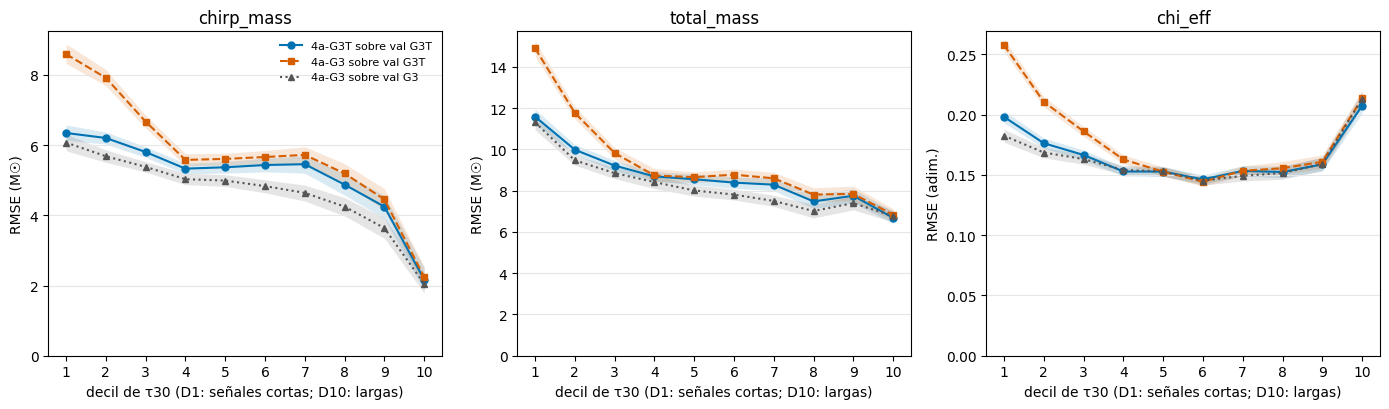

/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
/tmp/ipykernel_7569/1106250146.py:33: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]


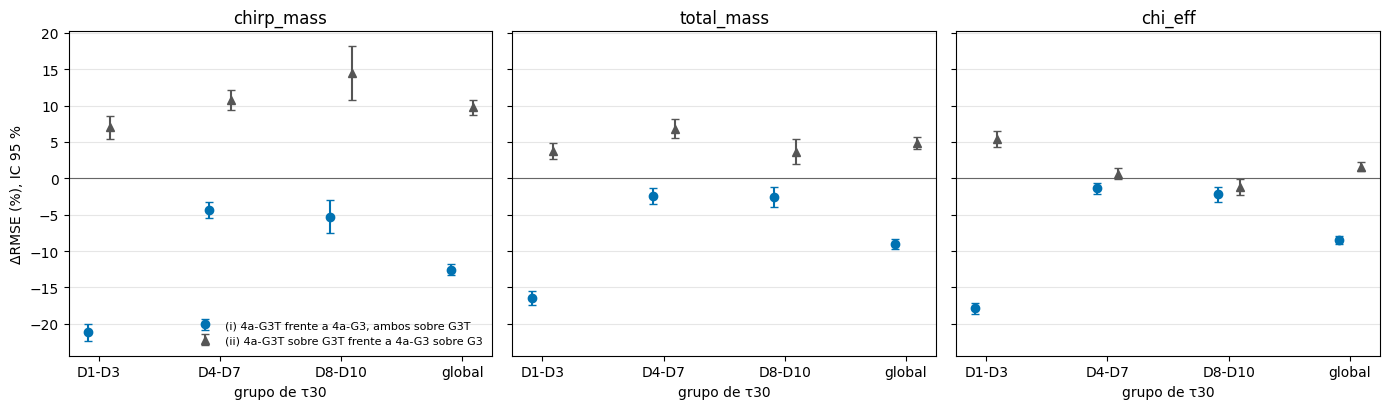

In [8]:
# 7. Figuras
FIG_DIR.mkdir(parents=True, exist_ok=True)
UNITS = {'chirp_mass': 'M☉', 'total_mass': 'M☉', 'chi_eff': 'adim.'}
# Fixed colour per entity; marker and line style carry identity without colour.
STYLE = {'G3T_on_G3T': dict(color='#0072B2', marker='o', ls='-'),
         'G3_on_G3T': dict(color='#D55E00', marker='s', ls='--'),
         'G3_on_G3': dict(color='#555555', marker='^', ls=':')}
COMPARISONS = {'drmse_pct_i': dict(name='(i) 4a-G3T frente a 4a-G3, ambos sobre G3T', color='#0072B2', marker='o'),
               'drmse_pct_ii': dict(name='(ii) 4a-G3T sobre G3T frente a 4a-G3 sobre G3', color='#555555', marker='^')}
Tk = T.set_index(['quantity', 'label', 'group'])

fig1, axes = plt.subplots(1, 3, figsize=(14, 4.2))
x = np.arange(1, 11)
for ax, lab in zip(axes, LABELS):
    for c in CASES:
        t = Tk.loc[(f'rmse_{c}', lab)].loc[DEC]
        s = STYLE[c]
        ax.fill_between(x, t.ci95_lo, t.ci95_hi, color=s['color'], alpha=0.15, lw=0)
        ax.plot(x, t.value, color=s['color'], marker=s['marker'], ls=s['ls'], lw=1.5, ms=5, label=CASE_NAME[c])
    ax.set(title=lab, xlabel='decil de τ30 (D1: señales cortas; D10: largas)', ylabel=f'RMSE ({UNITS[lab]})', xticks=x)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', color='0.9', lw=0.8)
axes[0].legend(fontsize=8, frameon=False)
fig1.tight_layout()
fig1.savefig(FIG_DIR / f'M13_13_rmse_by_decile_{RUN_UTC}.png', dpi=200)
plt.show()

PLOT_GROUPS = TAU_GROUPS + ['global']
fig2, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
x = np.arange(len(PLOT_GROUPS))
for ax, lab in zip(axes, LABELS):
    for off, (q, s) in zip((-0.09, 0.09), COMPARISONS.items()):
        t = Tk.loc[(q, lab)].loc[PLOT_GROUPS]
        ax.errorbar(x + off, t.value, yerr=[t.value - t.ci95_lo, t.ci95_hi - t.value], fmt=s['marker'], color=s['color'],
                    ms=6, lw=1.5, capsize=3, label=s['name'])
    ax.axhline(0, color='0.4', lw=0.8)
    ax.set(title=lab, xlabel='grupo de τ30', xticks=x, xticklabels=PLOT_GROUPS)
    ax.grid(axis='y', color='0.9', lw=0.8)
axes[0].set_ylabel('ΔRMSE (%), IC 95 %')
axes[0].legend(fontsize=8, frameon=False)
fig2.tight_layout()
fig2.savefig(FIG_DIR / f'M13_13_drmse_by_tau_group_{RUN_UTC}.png', dpi=200)
plt.show()

In [9]:
# 8. Resumen JSON (modo 'x': nunca sobrescribe)
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary = dict(
    experiment='M13.13', run_utc=RUN_UTC, preregistration='docs/experiments/M13_13_G3T_taper.md', split='val', n_val=N,
    note='Descriptive. G3T is adopted as the base for correctness, not performance. CIs: row sampling, not seed variation.',
    labels=LABELS, cases=CASE_NAME,
    comparisons=dict(drmse_pct_i='4a-G3T vs 4a-G3, both on val G3T', drmse_pct_ii='4a-G3T on val G3T vs 4a-G3 on val G3'),
    settings=dict(n_boot=N_BOOT, seed=SEED, paug1_min=PAUG1_MIN, paug2_max_pct=PAUG2_MAX_PCT, y_rtol=Y_RTOL, y_atol=Y_ATOL),
    inputs={k: dict(path=str(p), sha256=sha[k]) for k, p in all_files.items()},
    prediction_sources={c: dict(checkpoint=pred[c]['ckpt'], memmap_dir=pred[c]['memmap_dir'], units=pred[c]['units']) for c in CASES},
    tau_edges_s=tau_edges.tolist(), group_sizes={k: int(g.sum()) for k, g in GROUPS.items()},
    gates=dict(passed=True, n_checks=len(checks), checks=checks),
    health=health, measures=json.loads(T.to_json(orient='records')))

out_path = OUT_DIR / f'M13_13_G3T_evaluation_summary_{RUN_UTC}.json'
with open(out_path, 'x') as fh:
    json.dump(summary, fh, indent=1, ensure_ascii=False)
print(out_path)

/data/vserrano/cbc_pe_data/results/M13_3/M13_13/M13_13_G3T_evaluation_summary_20261110T124625Z.json
